# Question 8: LILA access and food-shelf site presence

Exploratory analysis of USDA LILA flags and food-shelf-type organizations across Minnesota's 2020 census tracts. This notebook creates statewide and Twin Cities tract maps and summarizes how sites are distributed across LILA and non-LILA tracts.

**Interpretation limit:** a site in a tract does not mean every resident can reach it. These are tract-level presence summaries, not population-weighted distance coverage or measures of site capacity, hours, or eligibility. The crosswalked Atlas flags are 2019-era data on 2010 tract geography.

In [1]:
#pip install -r ../requirements.txt

In [2]:
from pathlib import Path
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from shapely.geometry import box
from scipy.spatial.distance import cdist

# Find the repository root so the notebook works from the repo or notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "config.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find repository root containing src/config.py")
sys.path.insert(0, str(ROOT / "src"))
import config as C
import qkit

BOUNDARIES = (C.EXTERNAL / "census" / "tract" / "tl_2020_27_tract"
              / "tl_2020_27_tract.shp")
LILA_DATA = C.PROCESSED / "lila_tracts_2020.parquet"
POP_CENTERS = C.EXTERNAL / "census" / "gazetteer" / "CenPop2020_Mean_TR27.txt"
TRACT_GAZETTEER = C.EXTERNAL / "census" / "gazetteer" / "2026_Gaz_tracts_national.txt"
LILA_FLAG = "LILATracts_halfAnd10"
SITE_WINDOW_START = 202508
STATEWIDE_OUTPUT = C.FIG / "08_q8_lila_site_presence.png"
TWIN_CITIES_OUTPUT = C.FIG / "08_q8_lila_site_presence_twin_cities.png"
DISTANCE_OUTPUT = C.FIG / "08_q8_population_weighted_distance.png"
TWIN_CITIES_BOUNDS = (-94.15, 44.45, -92.45, 45.45)

for path in (BOUNDARIES, LILA_DATA,
             POP_CENTERS, TRACT_GAZETTEER, C.P_SITES):
    if not path.exists():
        raise FileNotFoundError(f"Required Q8 input not found: {path}")

## Load tract flags, site locations, and boundaries

Use food-shelf-like sites with a usable activity record in the latest 12 complete months (August 2025–July 2026). Exclude the broad `Agency or Tribal Nation` category, sites without a tract, and ZIP-centroid locations. Site locations are summarized by their assigned tract, not plotted as addresses.

In [3]:
tracts = gpd.read_file(BOUNDARIES)
if "GEOID" not in tracts.columns:
    raise ValueError("TIGER/Line shapefile is missing its GEOID tract key")
tracts["tract_geoid"] = tracts["GEOID"].astype(str).str.zfill(11)

lila = pd.read_parquet(LILA_DATA)
if LILA_FLAG not in lila.columns:
    raise ValueError(f"Crosswalk is missing required flag: {LILA_FLAG}")
if lila["tract_geoid"].duplicated().any():
    raise ValueError("Crosswalk contains duplicate 2020 tract GEOIDs")

site_master = pd.read_parquet(C.P_SITES)
sites = qkit.sites(food_shelf_only=True, reporting_only=True)
sites = sites[
    sites["state_fips"].astype(str).eq(C.STATE_FIPS_MN)
    & sites["last_yearmonth"].between(SITE_WINDOW_START, C.TRAIN_CUTOFF_YM)
    & ~sites["agency_type_clean"].eq("Agency or Tribal Nation")
].copy()
placeable = sites[
    sites["has_geoid"].fillna(False).astype(bool)
    & ~sites["geoid_is_zip_centroid"].fillna(False).astype(bool)
].copy()

site_counts = (placeable.groupby("tract_geoid")["site_id"]
               .nunique().rename("site_count").reset_index())
map_data = tracts.merge(lila[["tract_geoid", LILA_FLAG]], on="tract_geoid",
                        how="left", validate="one_to_one")
map_data = map_data.merge(site_counts, on="tract_geoid", how="left",
                          validate="one_to_one")
map_data["site_count"] = map_data["site_count"].fillna(0).astype(int)
map_data["has_site"] = map_data["site_count"].gt(0)
centers_raw = pd.read_csv(POP_CENTERS, dtype=str, encoding="utf-8-sig")
centers_raw["tract_geoid"] = (centers_raw["STATEFP"] + centers_raw["COUNTYFP"]
                              + centers_raw["TRACTCE"])
centers_raw["population"] = pd.to_numeric(centers_raw["POPULATION"], errors="coerce")
map_data = map_data.merge(
    centers_raw[["tract_geoid", "population"]], on="tract_geoid",
    how="left", validate="one_to_one")
zero_population_tracts = int(map_data["population"].eq(0).sum())
map_data = map_data[map_data["population"].gt(0)].copy()

if map_data.crs is None:
    raise ValueError("TIGER/Line tract file has no coordinate reference system")
map_data = map_data.to_crs("EPSG:26915")
print(f"Boundary tracts: {len(tracts):,}")
print(f"Recent placeable food-shelf sites: {len(placeable):,}")
print(f"Tracts with at least one such site: {int(map_data['has_site'].sum()):,}")
print(f"Zero-population tracts omitted from the map: {zero_population_tracts:,}")
print(f"Tracts with unavailable LILA status: {int(map_data[LILA_FLAG].isna().sum()):,}")

Boundary tracts: 1,505
Recent placeable food-shelf sites: 402
Tracts with at least one such site: 358
Zero-population tracts omitted from the map: 4
Tracts with unavailable LILA status: 0


## Exploratory summaries

These tables describe tract and organization counts. They do **not** estimate the share of people served or within reach.

In [4]:
map_data["lila_class"] = map_data[LILA_FLAG].map(
    {True: "LILA", False: "Non-LILA"}
).fillna("Unavailable")

tract_summary = (map_data.groupby("lila_class", observed=True)
                 .agg(tracts=("tract_geoid", "nunique"),
                      tracts_with_site=("has_site", "sum"),
                      site_organizations=("site_count", "sum"),
                      median_sites_per_tract=("site_count", "median")))
tract_summary["pct_tracts_with_site"] = (
    100 * tract_summary["tracts_with_site"] / tract_summary["tracts"]
)
tract_summary

,tracts,tracts_with_site,site_organizations,median_sites_per_tract,pct_tracts_with_site
lila_class,,,,,
LILA,393,123,144,0.0,31.297710
Non-LILA,1108,235,258,0.0,21.209386


In [5]:
# Inspect how much tract-boundary ambiguity remains after the crosswalk.
crosswalk = pd.read_parquet(LILA_DATA)
parent_summary = (crosswalk.groupby("parent_count", as_index=False)
                  .agg(tracts=("tract_geoid", "size")))
parent_summary["pct_2020_tracts"] = (
    100 * parent_summary["tracts"] / len(crosswalk)
)
all_parent_summary = (crosswalk.groupby("parent_count_all", as_index=False)
                       .agg(tracts=("tract_geoid", "size")))
all_parent_summary["pct_2020_tracts"] = (
    100 * all_parent_summary["tracts"] / len(crosswalk)
)
display(parent_summary)
all_parent_summary

,parent_count,tracts,pct_2020_tracts
0,0,3,0.199336
1,1,1479,98.272425
2,2,22,1.461794
3,3,1,0.066445


,parent_count_all,tracts,pct_2020_tracts
0,1,692,45.980066
1,2,514,34.152824
2,3,187,12.425249
3,4,70,4.651163
4,5,26,1.727575
5,6,11,0.730897
6,7,3,0.199336
7,8,1,0.066445
8,9,1,0.066445


`parent_count` counts only 2010 parents covering at least 5% of a 2020 tract's land area; `parent_count_all` includes even tiny sliver overlaps. The LILA share fields preserve the area-weighted values used for the 0.5 classification threshold.

In [6]:
COLORS = {
    "LILA tract with site": "#238b8e",
    "LILA tract without site": "#e76f51",
    "Non-LILA tract with site": "#82a876",
    "Non-LILA tract without site": "#edf0f2",
    "LILA status unavailable": "#b8b8b8",
}
known_lila = map_data[LILA_FLAG].notna()
is_lila = map_data[LILA_FLAG].astype("boolean").fillna(False)
map_data["map_category"] = "LILA status unavailable"
map_data.loc[known_lila & is_lila & map_data["has_site"], "map_category"] = "LILA tract with site"
map_data.loc[known_lila & is_lila & ~map_data["has_site"], "map_category"] = "LILA tract without site"
map_data.loc[known_lila & ~is_lila & map_data["has_site"], "map_category"] = "Non-LILA tract with site"
map_data.loc[known_lila & ~is_lila & ~map_data["has_site"], "map_category"] = "Non-LILA tract without site"

def draw_map(data, title, extent=None):
    fig, ax = plt.subplots(figsize=(10, 9) if extent else (10, 10))
    for category, color in COLORS.items():
        subset = data[data["map_category"].eq(category)]
        if not subset.empty:
            subset.plot(ax=ax, color=color,
                        linewidth=0.25 if extent else 0.12,
                        edgecolor="white")
    if extent:
        projected_extent = gpd.GeoSeries(
            [box(extent[0], extent[1], extent[2], extent[3])],
            crs="EPSG:4326").to_crs(data.crs)
        xmin, ymin, xmax, ymax = projected_extent.total_bounds
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
    fig.suptitle(title, x=0.5, y=0.97, fontsize=15, fontweight="bold")
    fig.text(0.5, 0.935,
             "2020 tract boundaries | USDA 2019 half-mile/10-mile LILA definition",
             ha="center", fontsize=10, color="#444444")
    fig.legend(handles=[Patch(facecolor=color, edgecolor="white", label=label)
                        for label, color in COLORS.items()
                        if data["map_category"].eq(label).any()],
               title="Tract classification", loc="lower center",
               bbox_to_anchor=(0.5, 0.02), ncol=2,
               frameon=True, framealpha=0.95)
    fig.text(0.5, 0.14,
             "Zero-population tracts omitted. Site points use tract internal points, not addresses.",
             ha="center", fontsize=8, color="#444444")
    ax.set_axis_off()
    fig.subplots_adjust(top=0.91, bottom=0.22)
    fig.savefig(output, dpi=220)
    plt.show()
    plt.close(fig)

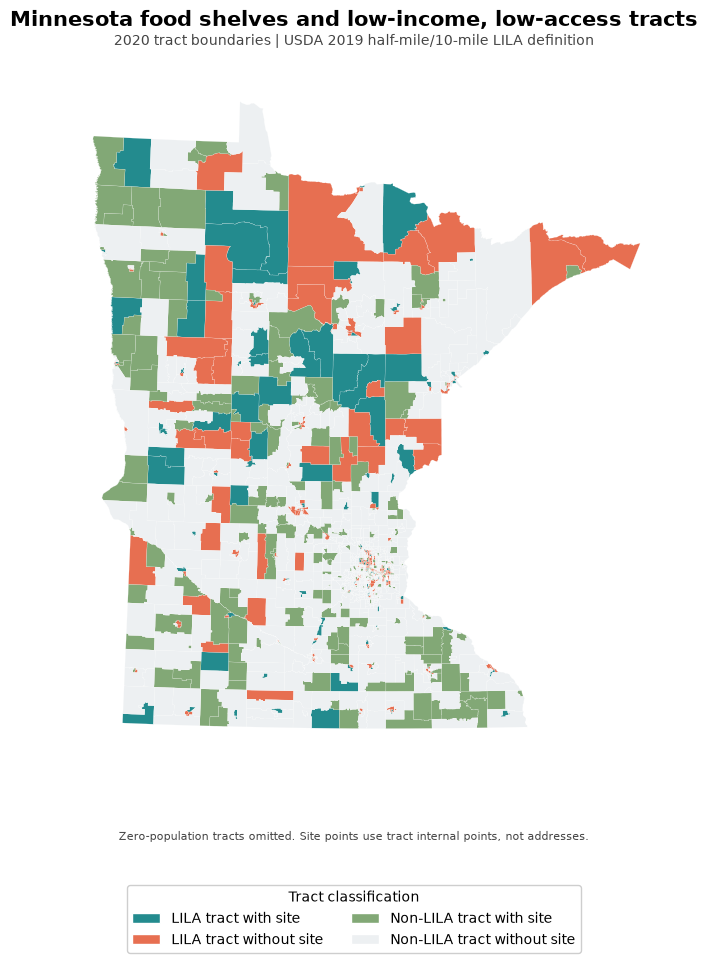

Saved outputs/figures/08_q8_lila_site_presence.png


In [7]:
output = STATEWIDE_OUTPUT
draw_map(map_data, "Minnesota food shelves and low-income, low-access tracts")
print(f"Saved {output.relative_to(ROOT)}")

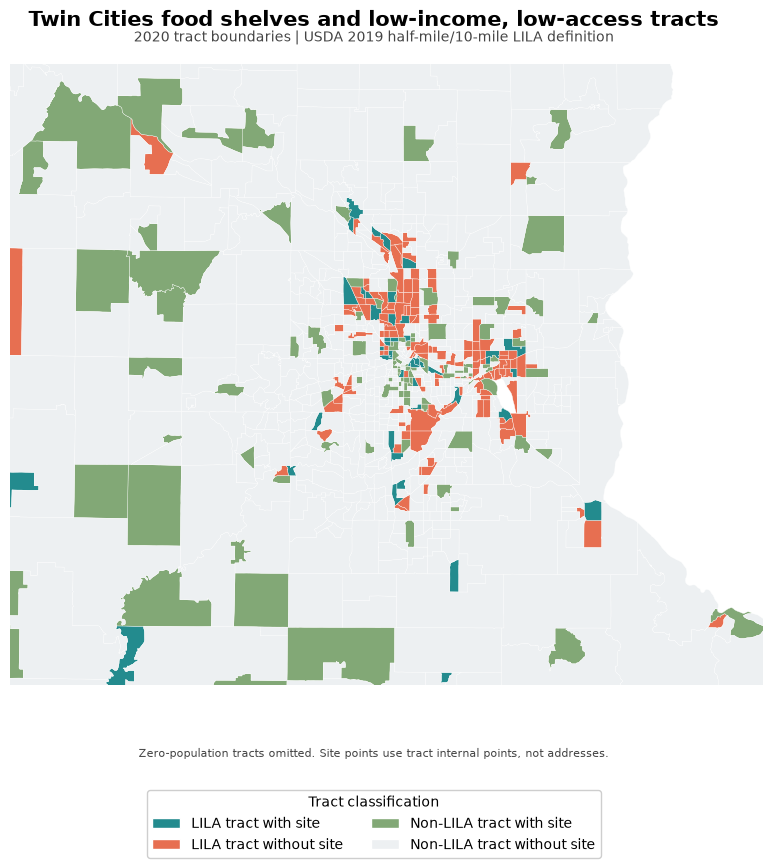

Saved outputs/figures/08_q8_lila_site_presence_twin_cities.png


In [8]:
output = TWIN_CITIES_OUTPUT
draw_map(map_data,
         "Twin Cities food shelves and low-income, low-access tracts",
         extent=TWIN_CITIES_BOUNDS)
print(f"Saved {output.relative_to(ROOT)}")

## Join and crosswalk diagnostics

Before interpreting the maps or summaries, verify that tract keys line up across the TIGER polygons, crosswalk, and 2020 population centers. A missing LILA flag is not the same as a non-LILA tract.

In [9]:
centers_raw = pd.read_csv(POP_CENTERS, dtype=str, encoding="utf-8-sig")
centers_raw["tract_geoid"] = (centers_raw["STATEFP"] + centers_raw["COUNTYFP"]
                              + centers_raw["TRACTCE"])
boundary_ids = set(tracts["tract_geoid"])
crosswalk_ids = set(lila["tract_geoid"])
population_ids = set(centers_raw["tract_geoid"])
join_audit = pd.DataFrame([
    {"source": "2020 tract boundaries", "tracts": len(boundary_ids),
     "overlap_with_boundaries": len(boundary_ids), "unmatched": 0},
    {"source": "LILA crosswalk", "tracts": len(crosswalk_ids),
     "overlap_with_boundaries": len(boundary_ids & crosswalk_ids),
     "unmatched": len(crosswalk_ids - boundary_ids)},
    {"source": "2020 population centers", "tracts": len(population_ids),
     "overlap_with_boundaries": len(boundary_ids & population_ids),
     "unmatched": len(population_ids - boundary_ids)},
])
assert tracts["tract_geoid"].is_unique
assert lila["tract_geoid"].is_unique
assert centers_raw["tract_geoid"].is_unique
join_audit

,source,tracts,overlap_with_boundaries,unmatched
0,2020 tract boundaries,1505,1505,0
1,LILA crosswalk,1505,1505,0
2,2020 population centers,1505,1505,0


In [10]:
# Inspect borderline weighted shares under the project's 0.5 classification rule.
share_columns = [f"{flag}_share" for flag in [
    "LILATracts_halfAnd10", "LILATracts_1And10",
    "LILATracts_1And20", "LILATracts_Vehicle"]]
crosswalk_sensitivity = []
for share_column in share_columns:
    shares = lila[share_column]
    crosswalk_sensitivity.append({
        "flag": share_column.removesuffix("_share"),
        "tracts_with_defined_share": int(shares.notna().sum()),
        "tracts_near_cutoff_0.4_to_0.6": int(shares.between(0.4, 0.6, inclusive="both").sum()),
        "tracts_changed_if_cutoff_0.4_vs_0.6": int(
            ((shares.ge(0.4)) != (shares.ge(0.6))).sum()),
    })
pd.DataFrame(crosswalk_sensitivity)

,flag,tracts_with_defined_share,tracts_near_cutoff_0.4_to_0.6,tracts_changed_if_cutoff_0.4_vs_0.6
0,LILATracts_halfAnd10,1501,1,1
1,LILATracts_1And10,1501,0,0
2,LILATracts_1And20,1501,0,0
3,LILATracts_Vehicle,1501,0,0


## Site inclusion and clustering

The location master describes organizations, not current operating hours or capacity. The shared food-shelf-type definition is used here, and ZIP-centroid GEOIDs are excluded from distance calculations.

In [11]:
is_minnesota = site_master["state_fips"].astype(str).eq(C.STATE_FIPS_MN)
mn_sites = site_master[is_minnesota].copy()
mn_shelf_type = mn_sites[mn_sites["is_food_shelf_like"].fillna(False)]
mn_reported = mn_shelf_type[mn_shelf_type["ever_reported"].fillna(False)]
mn_recent = mn_reported[mn_reported["last_yearmonth"].between(
    SITE_WINDOW_START, C.TRAIN_CUTOFF_YM)]
mn_q8_type = mn_recent[~mn_recent["agency_type_clean"].eq("Agency or Tribal Nation")]
mn_placeable = mn_q8_type[mn_q8_type["has_geoid"].fillna(False)
                           & ~mn_q8_type["geoid_is_zip_centroid"].fillna(False)]
site_audit = pd.DataFrame([
    {"site_group": "Organizations with state_fips = 27", "organizations": mn_sites["site_id"].nunique()},
    {"site_group": "Food-shelf-like organizations", "organizations": mn_shelf_type["site_id"].nunique()},
    {"site_group": "Ever reported food-shelf-like", "organizations": mn_reported["site_id"].nunique()},
    {"site_group": "Latest 12-month reporters before type exclusion", "organizations": mn_recent["site_id"].nunique()},
    {"site_group": "Agency or Tribal Nation sites excluded", "organizations": mn_recent.loc[mn_recent["agency_type_clean"].eq("Agency or Tribal Nation"), "site_id"].nunique()},
    {"site_group": "Latest 12-month reporters after type exclusion", "organizations": mn_q8_type["site_id"].nunique()},
    {"site_group": "Q8 sites without tract geoid", "organizations": int((~mn_q8_type["has_geoid"].fillna(False)).sum())},
    {"site_group": "Q8 sites with ZIP-centroid geoid", "organizations": int(mn_q8_type["geoid_is_zip_centroid"].fillna(False).sum())},
    {"site_group": "Q8 sites with usable tract locations", "organizations": mn_placeable["site_id"].nunique()},
])
display(site_audit)

site_count_distribution = (map_data["site_count"].value_counts().sort_index()
                           .rename_axis("sites_in_tract").rename("tracts").to_frame())
site_count_distribution["pct_tracts"] = 100 * site_count_distribution["tracts"] / len(map_data)
site_count_distribution

,site_group,organizations
0,Organizations with state_fips = 27,1051
1,Food-shelf-like organizations,726
2,Ever reported food-shelf-like,446
3,Latest 12-month reporters before type exclusion,415
4,Agency or Tribal Nation sites excluded,13
5,Latest 12-month reporters after type exclusion,402
6,Q8 sites without tract geoid,0
7,Q8 sites with ZIP-centroid geoid,0
8,Q8 sites with usable tract locations,402


,tracts,pct_tracts
sites_in_tract,,
0,1143,76.149234
1,322,21.452365
2,30,1.998668
3,5,0.333111
5,1,0.066622


## Exploratory nearest-site distance and population coverage

Approximate each resident population by the Census 2020 tract center of population and each food-shelf organization by its assigned tract's Census Gazetteer internal point. Distances are straight-line miles in a Minnesota-appropriate projected CRS—not road travel, address-level distance, or a service-area measure. Population weights come from the 2020 Census tract center file.

In [12]:
centers = centers_raw.copy()
centers["population"] = pd.to_numeric(centers["POPULATION"], errors="coerce")
centers["latitude"] = pd.to_numeric(centers["LATITUDE"], errors="coerce")
centers["longitude"] = pd.to_numeric(centers["LONGITUDE"], errors="coerce")
gazetteer = pd.read_csv(TRACT_GAZETTEER, sep="|", dtype=str, encoding="utf-8-sig")
gazetteer.columns = gazetteer.columns.str.strip()
gazetteer = gazetteer[gazetteer["GEOID"].str.startswith(C.STATE_FIPS_MN)].copy()
gazetteer["latitude"] = pd.to_numeric(gazetteer["INTPTLAT"], errors="coerce")
gazetteer["longitude"] = pd.to_numeric(gazetteer["INTPTLONG"], errors="coerce")
site_tracts = site_counts[["tract_geoid"]].drop_duplicates().merge(
    gazetteer[["GEOID", "latitude", "longitude"]],
    left_on="tract_geoid", right_on="GEOID", how="left", validate="one_to_one")
if site_tracts[["latitude", "longitude"]].isna().any(axis=None):
    raise ValueError("Some food-shelf site tracts have no Gazetteer coordinates")

center_points = gpd.GeoDataFrame(
    centers, geometry=gpd.points_from_xy(centers["longitude"], centers["latitude"]),
    crs="EPSG:4326").to_crs("EPSG:26915")
site_points = gpd.GeoDataFrame(
    site_tracts, geometry=gpd.points_from_xy(site_tracts["longitude"], site_tracts["latitude"]),
    crs="EPSG:4326").to_crs("EPSG:26915")
center_xy = np.column_stack([center_points.geometry.x, center_points.geometry.y])
site_xy = np.column_stack([site_points.geometry.x, site_points.geometry.y])
nearest_miles = cdist(center_xy, site_xy).min(axis=1) / 1609.344

distance_data = centers[["tract_geoid", "population"]].copy()
distance_data["nearest_site_miles"] = nearest_miles
distance_data = distance_data.merge(lila, on="tract_geoid", how="left", validate="one_to_one")
distance_data = distance_data.merge(site_counts, on="tract_geoid", how="left", validate="one_to_one")
distance_data["site_count"] = distance_data["site_count"].fillna(0).astype(int)
distance_data["lila_class"] = distance_data[LILA_FLAG].map({True: "LILA", False: "Non-LILA"}).fillna("Unavailable")
distance_data["urban_rural"] = distance_data["Urban"].map({True: "Urban", False: "Rural"}).fillna("Unavailable")
distance_data[["population", "nearest_site_miles"]].describe(percentiles=[.5, .9, .95])

,population,nearest_site_miles
count,1505.000000,1505.000000
mean,3791.690365,3.221937
std,1472.806389,3.685404
min,0.000000,0.005600
50%,3587.000000,1.951873
90%,5705.600000,7.923665
95%,6360.800000,10.973696
max,13470.000000,32.042409


### Weighted coverage by LILA and urban/rural status

Each reported coverage percentage weights tracts by the number of residents in the tract. These thresholds are exploratory straight-line distance bands; they should not be interpreted as actual travel time or service availability.

In [13]:
def summarize_coverage(group):
    group = group[group["population"].gt(0) & group["nearest_site_miles"].notna()]
    if group.empty:
        return pd.Series({"tracts": 0, "population": 0,
                          "weighted_mean_nearest_miles": np.nan,
                          **{f"population_within_{cutoff}_mi_pct": np.nan
                             for cutoff in (1, 5, 10)}})
    weights = group["population"].to_numpy(dtype=float)
    miles = group["nearest_site_miles"].to_numpy(dtype=float)
    total_population = weights.sum()
    return pd.Series({
        "tracts": len(group),
        "population": int(total_population),
        "weighted_mean_nearest_miles": np.average(miles, weights=weights),
        **{f"population_within_{cutoff}_mi_pct": 100 * weights[miles <= cutoff].sum() / total_population
           for cutoff in (1, 5, 10)},
    })

coverage = (distance_data[distance_data["lila_class"].ne("Unavailable")
                          & distance_data["urban_rural"].ne("Unavailable")]
            .groupby(["lila_class", "urban_rural"], observed=True)
            .apply(summarize_coverage, include_groups=False)
            .reset_index())
coverage

,lila_class,urban_rural,tracts,population,weighted_mean_nearest_miles,population_within_1_mi_pct,population_within_5_mi_pct,population_within_10_mi_pct
0,LILA,Rural,65.0,171240.0,8.015014,1.386942,37.010044,64.702172
1,LILA,Urban,328.0,1244690.0,1.357804,45.035390,98.052125,99.310672
2,Non-LILA,Rural,423.0,1471953.0,5.409825,5.635914,55.256588,88.630819
3,Non-LILA,Urban,685.0,2818611.0,2.032451,25.370759,95.212961,99.887356


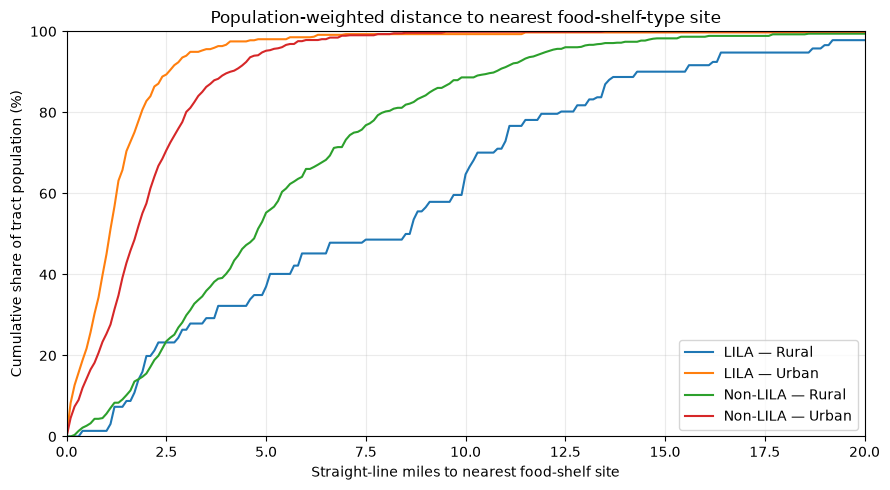

Saved outputs/figures/08_q8_population_weighted_distance.png


In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
distance_grid = np.linspace(0, 20, 201)
cdf_data = distance_data[distance_data["population"].gt(0)
                         & distance_data["lila_class"].ne("Unavailable")
                         & distance_data["urban_rural"].ne("Unavailable")]
for (lila_class, urban_rural), group in cdf_data.groupby(
        ["lila_class", "urban_rural"], observed=True):
    group = group[group["population"].gt(0) & group["nearest_site_miles"].notna()]
    weights = group["population"].to_numpy(dtype=float)
    miles = group["nearest_site_miles"].to_numpy(dtype=float)
    weighted_cdf = [100 * weights[miles <= cutoff].sum() / weights.sum()
                    for cutoff in distance_grid]
    ax.plot(distance_grid, weighted_cdf, label=f"{lila_class} — {urban_rural}")
ax.set(xlabel="Straight-line miles to nearest food-shelf site",
       ylabel="Cumulative share of tract population (%)",
       title="Population-weighted distance to nearest food-shelf-type site")
ax.set_xlim(0, 20)
ax.set_ylim(0, 100)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(DISTANCE_OUTPUT, dpi=220, bbox_inches="tight")
plt.show()
print(f"Saved {DISTANCE_OUTPUT.relative_to(ROOT)}")

Re-run the cells below after rebuilding `lila_tracts_2020.parquet` and updating the site definition. Coverage estimates use tract centers of population and tract internal points for sites; they are straight-line approximations, not driving distances or proof that a site has capacity, suitable hours, or serves nearby residents. Four zero-population tracts are excluded from population-weighted estimates.

### LILA definition sensitivity

The USDA Atlas has several LILA definitions. Comparing them shows whether initial site-presence and coverage patterns depend on the chosen threshold/vehicle-access definition. These remain area-weighted 2010-to-2020 classifications.

In [15]:
sensitivity_rows = []
for flag in ["LILATracts_halfAnd10", "LILATracts_1And10",
             "LILATracts_1And20", "LILATracts_Vehicle"]:
    valid = distance_data[flag].notna() & distance_data["population"].gt(0)
    group = distance_data.loc[valid].copy()
    is_lila = group[flag].astype("boolean").fillna(False)
    group = group.loc[is_lila]
    weights = group["population"].to_numpy(dtype=float)
    miles = group["nearest_site_miles"].to_numpy(dtype=float)
    sensitivity_rows.append({
        "definition": flag,
        "LILA_tracts": len(group),
        "LILA_population": int(weights.sum()),
        "LILA_tracts_with_site_pct": 100 * group["site_count"].gt(0).mean(),
        "LILA_population_within_5_miles_pct": 100 * weights[miles <= 5].sum() / weights.sum(),
    })
pd.DataFrame(sensitivity_rows)

,definition,LILA_tracts,LILA_population,LILA_tracts_with_site_pct,LILA_population_within_5_miles_pct
0,LILATracts_halfAnd10,393,1415930,31.297710,90.669807
1,LILATracts_1And10,217,765067,33.640553,83.180166
2,LILATracts_1And20,157,604772,28.025478,95.274748
3,LILATracts_Vehicle,164,645973,33.536585,93.980089


## Exploratory comparison with grocery access

`LAhalfand10` and `LA1and10` are USDA Atlas low-access-to-supermarket flags (not food-shelf measures). They are area-weighted onto 2020 tracts by the shared crosswalk builder. Comparisons are split by USDA urban/rural status because low-access groups differ substantially by geography; they do not establish that a shelf substitutes for a grocery store.

In [16]:
retail_rows = []
for flag in ["LAhalfand10", "LA1and10"]:
    for (low_access, urban), group in distance_data.groupby(
            [flag, "Urban"], dropna=False, observed=True):
        group = group[group["population"].gt(0)]
        label = "Unavailable" if pd.isna(low_access) else ("Low grocery access" if low_access else "Not low grocery access")
        urban_label = "Unavailable" if pd.isna(urban) else ("Urban" if urban else "Rural")
        if group.empty:
            continue
        summary = summarize_coverage(group)
        retail_rows.append({"USDA_grocery_flag": flag, "retail_group": label,
                            "urban_rural": urban_label,
                            **summary.to_dict(),
                            "tracts_with_shelf_site_pct": 100 * group["site_count"].gt(0).mean()})
retail_access_summary = pd.DataFrame(retail_rows)
retail_access_summary

,USDA_grocery_flag,retail_group,urban_rural,tracts,population,weighted_mean_nearest_miles,population_within_1_mi_pct,population_within_5_mi_pct,population_within_10_mi_pct,tracts_with_shelf_site_pct
0,LAhalfand10,Not low grocery access,Rural,333.0,1208596.0,4.937498,6.045279,58.383116,92.314802,30.330330
1,LAhalfand10,Not low grocery access,Urban,106.0,328871.0,0.630707,80.435490,100.000000,100.000000,38.679245
2,LAhalfand10,Low grocery access,Rural,155.0,434597.0,7.749845,2.823305,39.372338,68.957448,32.903226
3,LAhalfand10,Low grocery access,Urban,907.0,3734430.0,1.931035,27.075752,95.737690,99.685226,18.191841
4,LA1and10,Not low grocery access,Rural,333.0,1208596.0,4.937498,6.045279,58.383116,92.314802,30.330330
5,LA1and10,Not low grocery access,Urban,444.0,1594704.0,1.189784,50.849186,99.117266,99.586067,25.225225
6,LA1and10,Low grocery access,Rural,155.0,434597.0,7.749845,2.823305,39.372338,68.957448,32.903226
7,LA1and10,Low grocery access,Urban,569.0,2468597.0,2.236648,18.826888,94.122329,99.791217,16.520211


### Cross-classify LILA status and USDA grocery-access status

This table isolates the tracts identified as low-income/low-access from those identified as low supermarket access only. A large site distance in a grocery-low-access tract is a potential network gap; a short estimated site distance suggests proximity, but not capacity or eligibility.

In [17]:
retail_lila_rows = []
for (lila_status, grocery_status, urban_rural), group in distance_data.groupby(
        ["lila_class", "LAhalfand10", "urban_rural"], dropna=False, observed=True):
    if group["population"].gt(0).sum() == 0:
        continue
    summary = summarize_coverage(group)
    retail_lila_rows.append({
        "lila_status": lila_status,
        "usda_low_grocery_access": grocery_status,
        "urban_rural": urban_rural,
        **summary.to_dict(),
        "tracts_with_shelf_site_pct": 100 * group["site_count"].gt(0).mean(),
    })
pd.DataFrame(retail_lila_rows)

,lila_status,usda_low_grocery_access,urban_rural,tracts,population,weighted_mean_nearest_miles,population_within_1_mi_pct,population_within_5_mi_pct,population_within_10_mi_pct,tracts_with_shelf_site_pct
0,LILA,True,Rural,65.0,171240.0,8.015014,1.386942,37.010044,64.702172,46.153846
1,LILA,True,Urban,328.0,1244690.0,1.357804,45.035390,98.052125,99.310672,28.353659
2,Non-LILA,False,Rural,333.0,1208596.0,4.937498,6.045279,58.383116,92.314802,30.330330
3,Non-LILA,False,Urban,106.0,328871.0,0.630707,80.435490,100.000000,100.000000,38.679245
4,Non-LILA,True,Rural,90.0,263357.0,7.577426,3.757257,40.908349,71.724313,23.333333
5,Non-LILA,True,Urban,579.0,2489740.0,2.217608,18.097231,94.580639,99.872477,12.435233


## EDA interpretation and follow-up

- Read tract-presence maps together with the join audit and weighted distance table; none alone measures actual access to a site's services.
- The distance calculation uses tract centers/internal points and straight-line distance. Check rural outliers against driving routes before drawing strong access conclusions.
- The Atlas retail flags are a benchmark for supermarket access. Shelf co-location or shorter distance may suggest complementary reach, but capacity, hours, eligibility, and client residence are not observed.
- Treat the tables and figures here as exploration. Rebuild any statistics used in the final answer in `questions/q8_lila_access/analysis.py`.

Inputs: processed organization and Atlas extracts; Census 2010-to-2020 tract relationship file; Census 2020 tract population centers and Gazetteer; and 2020 Minnesota TIGER/Line tract boundaries.